In [1]:
import numpy as np
import xarray as xr
import cftime
import pandas as pd
import os
from scipy.stats import gaussian_kde
from scipy import stats

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.patches import Circle
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
import matplotlib.colors as mcolors
from matplotlib import colors


import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
lat = np.arange(-90, 91, 1)
lon = np.arange(0, 361, 1)

TC_path1d = r'../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/genesis-new-1d/'
TC_path2d = r'F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\genesis-new-2d\\'
TCT_path = r'../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/'
soda_path = r'F:\study\data\soda\\'
path_noaa = r'F:\study\data\noaa-20c\\'

In [72]:
(times - np.datetime64('1806-01')).astype(int)

(892597,)

In [2]:
cp = np.fromfile('./data/CP.txt', dtype='<U48').astype('datetime64[M]')
ep = np.fromfile('./data/EP.txt', dtype='<U48').astype('datetime64[M]')
mix = np.fromfile('./data/MIX.txt', dtype='<U48').astype('datetime64[M]')
suc = np.fromfile('./data/SUC.txt', dtype='<U48').astype('datetime64[M]')
cp = cp[cp < np.datetime64('2014-01')]
ep = ep[ep < np.datetime64('2014-01')]
mix = mix[mix < np.datetime64('2014-01')]
suc = suc[suc < np.datetime64('2014-01')]
events = [mix, ep, cp, suc]
# time = pd.date_range('1806-01', '2015-12', freq='MS')
# nt = len(time)
# nx, ny = len(lon), len(lat)
# ds_tct = xr.Dataset(
#     {
#         'tct':([], )
#     },
#     coords={
#         'time':(['time'], time),
#         'lat':(['lat'], lat),
#         'lon':(['lon'], lon)
#     }
# )
# tct_grid = np.zeros((nt, ny, nx))
tct = [[[] for i in range(24)] for j in range(3)]
for i in range(1, 2):
    file_name = TCT_path+f'merged_0{i:02d}.txt'
    print(file_name)
    df = pd.read_csv(file_name, header=None, sep=',', names=['lon', 'lat', 'intensity', 'time'], on_bad_lines='skip').dropna()
    times = df.loc[:, 'time'].to_numpy(dtype='datetime64[M]')
    LATS = df.loc[:, 'lat'].to_numpy(dtype='float32')
    LONS = df.loc[:, 'lon'].to_numpy(dtype='float32')
    ts = (times - np.datetime64('1806-01')).astype(int)
    ys = LATS + 90
    xs = LONS
    for j in range(3):
        event = events[j]
        for k in range(len(event)):
            for m in range(24):
                mask = times == event[k]+np.timedelta64(m, 'M')
                tct[j][m].append([LATS[mask], LONS[mask]])
#     for j in range(len(times)):
#         # print(j, end=',')
#         t, y, x = ts[j], ys[j], xs[j]
#         tct_grid[t, y-5:y+5, x-10:x+10] += 1
#     print(times[j], LATS[j], LONS[j])
# ds_tct.tct_grid[:] = tct_grid / 80
# ds_tct.to_netcdf('./data-20c/NOAA-20C_TCT_grid.nc')

F:\study\data\noaa-20c\NOAA\NOAA_20C_TXT_30_all_bing\\merged_001.txt


In [19]:
times[np.logical_and(times >= mix[0], times <= mix[0]+np.timedelta64(24))]

array(['1902-01', '1902-01', '1902-01', ..., '1903-12', '1903-12',
       '1903-12'], shape=(10599,), dtype='datetime64[M]')

In [2]:
time = pd.date_range('1806-01', '2015-12', freq='MS')
nt = len(time)
nx, ny = len(lon), len(lat)
ds_tct = xr.Dataset(
    {
        'tct_grid':(['time', 'lat', 'lon'], np.zeros((nt, ny, nx))),
    },
    coords={
        'time':(['time'], time),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)
tct_grid = np.zeros((nt, ny, nx))

for i in range(1, 81):
    file_name = TCT_path+f'merged_0{i:02d}.txt'
    print(file_name)
    df = pd.read_csv(file_name, header=None, sep=',', names=['lon', 'lat', 'intensity', 'time'], on_bad_lines='skip').dropna()
    times = df.loc[:, 'time'].to_numpy(dtype='datetime64[M]')
    LATS = df.loc[:, 'lat'].to_numpy(dtype='int32')
    LONS = df.loc[:, 'lon'].to_numpy(dtype='int32')
    ts = (times - np.datetime64('1806-01')).astype(int)
    ys = LATS + 90
    xs = LONS
    for j in range(len(times)):
        # print(j, end=',')
        t, y, x = ts[j], ys[j], xs[j]
        tct_grid[t, y-5:y+5, x-10:x+10] += 1
    print(times[j], LATS[j], LONS[j])
ds_tct.tct_grid[:] = tct_grid / 80
ds_tct.to_netcdf('./data-20c/NOAA-20C_TCT_grid.nc')

../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_001.txt
2014-12 12 95
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_002.txt
2014-12 10 108
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_003.txt
2014-11 36 226
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_004.txt
2014-12 17 216
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_005.txt
2014-11 21 156
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_006.txt
2014-11 59 169
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_007.txt
2014-11 68 177
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_008.txt
2014-11 58 168
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_009.txt
2014-12 6 98
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_010.txt
2014-11 59 170
../../../study/data/noaa-20c/NOAA/NOAA_20C_TXT_30_all_bing/merged_011.txt
2014-12 11 100
../../../study/data/noaa

In [2]:
time = pd.date_range('1806-01', '2015-12', freq='MS')
nt = len(time)
nx, ny = len(lon), len(lat)
ds_tc = xr.Dataset(
    {
        'tcg_grid':(['time', 'lat', 'lon'], np.zeros((nt, ny, nx))),
        'tcg_current':(['basin', 'time'], np.zeros((6, nt))),
        'tcg_series':(['basin', 'time'], np.zeros((6, nt))),
        'tcg_series_max':(['basin', 'time'], np.zeros((6, nt))),
        'tcg_series_min':(['basin', 'time'], np.zeros((6, nt))),
    },
    coords={
        'basin':(['basin'], ['SH', 'NS', 'NI', 'WNP', 'ENP', 'NA']),
        'time':(['time'], time),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)
ds_tc.tcg_series_min[:] = 1000
max_tc = np.zeros((6, nt))
min_tc = np.zeros_like(max_tc)
tcg_current = np.zeros((6, nt))
tcg_grid = np.zeros((nt, ny, nx))
for i in range(1, 81):
    print(i)
    loc = np.loadtxt(TC_path1d+f'Genesis_0{i:02d}.txt', usecols=[0, 1], delimiter=',')
    times = np.loadtxt(TC_path1d+f'Genesis_0{i:02d}.txt', usecols=[-1], delimiter=',', dtype='datetime64[M]')
    lons = loc[:, 0].astype(int)
    lats = loc[:, 1].astype(int) + 90
    nts = (times - np.datetime64('1806-01')).astype(int)
    for j in range(len(times)):
        # print(times[j])
        LON, LAT = lons[j], lats[j]
        if LAT-90 < 0:
            basin = 0
        else:
            if LON <= 100:
                basin = 2
            elif LON <= 180:
                basin = 3
            else:
                LON_ = -2.15*(LAT-90) + 298.05
                if LON <= LON_:
                    basin = 4
                else:
                    basin = 5
        # ds_tc.tcg_current.loc[basin, times[j]] += 1
        # ds_tc.tcg_grid.loc[times[j], LAT-5:LAT+5, LON-10:LON+10] += 1
        tcg_grid[nts[j], LAT-5:LAT+5, LON-10:LON+10] += 1
        tcg_current[basin, nts[j]] += 1

    ds_tc.tcg_current[:] = tcg_current
    ds_tc.tcg_series[:] += ds_tc.tcg_current[:]
    mask = ds_tc.tcg_current.values <= ds_tc.tcg_series_max.values
    ds_tc.tcg_series_max[:] = ds_tc.tcg_series_max.where(mask, ds_tc.tcg_current)
    mask = ds_tc.tcg_current.values >= ds_tc.tcg_series_min.values
    ds_tc.tcg_series_min[:] = ds_tc.tcg_series_min.where(mask, ds_tc.tcg_current)
    tcg_current[:] = 0
    
ds_tc.tcg_grid[:] = tcg_grid/80
ds_tc.tcg_series[:] /= 80

ds_tc.to_netcdf('./data-20c/NOAA-20C_TC_grid.nc')

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80


In [6]:
import netCDF4
netCDF4.Dataset("./data-20c/NOAA-20C_TCT_grid.nc", "r")

<class 'netCDF4._netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    dimensions(sizes): time(2520), lat(181), lon(361)
    variables(dimensions): float64 tct_grid(time, lat, lon), int64 time(time), int64 lat(lat), int64 lon(lon)
    groups: 

In [15]:
def composite_ttest(da, event_mask, dim='time', equal_var=False):

    event_mask = xr.DataArray(event_mask, dims=[dim], coords={dim: da[dim]})
    
    # 分组
    da_event = da.where(event_mask, drop=True)
    da_clim  = da.where(~event_mask, drop=True)
    
    # 合成均值
    composite = da_event.mean(dim=dim).values
    
    # 各组统计量
    n1 = da_event.count(dim=dim)
    n2 = da_clim.count(dim=dim)
    m1 = da_event.mean(dim=dim)
    m2 = da_clim.mean(dim=dim)
    v1 = da_event.var(dim=dim, ddof=1)
    v2 = da_clim.var(dim=dim, ddof=1)
    
    # t 统计量（Welch）
    se = np.sqrt(v1 / n1 + v2 / n2)
    t_stat = (m1 - m2) / se
    
    # 自由度（Welch–Satterthwaite）
    if equal_var:
        df = n1 + n2 - 2
        # 合并方差
        sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / df
        se = np.sqrt(sp2 * (1/n1 + 1/n2))
        t_stat = (m1 - m2) / se
    else:
        df = (v1/n1 + v2/n2)**2 / (
            (v1/n1)**2/(n1 - 1) + (v2/n2)**2/(n2 - 1)
        )
    
    # 双尾 p 值
    p_value = 2 * stats.t.sf(np.abs(t_stat), df)
    
    # 保持 xarray 结构
    # p_value = xr.DataArray(p_value, coords=t_stat.coords, dims=t_stat.dims)
    
    return composite, p_value

In [ ]:
tcg_grid.loc[tcg_grid.time.dt.month.isin(mon[0] % 12 + 1)]

<xarray.DataArray 'tcg_grid' (time: 116, lat: 181, lon: 361)>
array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
...
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]])
Coordinates:
  * time     (time) datetime64[ns] 1900-06-01 1901-06-01 ... 2015-06-01
  * lat      (lat) int32 -90 -89 -88 -87 -86 -85 -84 ... 84 85 86 87 88 89 90
  * lon      (lon) int32 0 1 2 3 4 5 6 7 8 ... 353 354 355 356 357 358 359 360

In [29]:
tcg_grid.time.dt.month.isin(mon[j] % 12)+1

<xarray.DataArray 'month' (time: 1392)>
array([1, 1, 1, ..., 1, 1, 1])
Coordinates:
  * time     (time) datetime64[ns] 1900-01-01 1900-02-01 ... 2015-12-01

In [59]:
cp = np.fromfile('./data/CP.txt', dtype='<U48').astype('datetime64[M]')
ep = np.fromfile('./data/EP.txt', dtype='<U48').astype('datetime64[M]')
mix = np.fromfile('./data/MIX.txt', dtype='<U48').astype('datetime64[M]')
suc = np.fromfile('./data/SUC.txt', dtype='<U48').astype('datetime64[M]')
cp = cp[cp < np.datetime64('2014-01')]
ep = ep[ep < np.datetime64('2014-01')]
mix = mix[mix < np.datetime64('2014-01')]
suc = suc[suc < np.datetime64('2014-01')]
events = [mix, cp, ep, suc]

tcg_grid = xr.open_dataset('./data-20c/NOAA-20C_TC_grid.nc').tcg_grid.loc['1900':'2015']
tct_grid = xr.open_dataset('./data-20c/NOAA-20C_TCT_grid.nc').tct_grid.loc['1900':'2015']
ssta = xr.open_dataset('./data/ssta.nc').sst.loc['1900':'2015']

rolling = lambda x: x.rolling(time=30, min_periods=1, center=True).mean()

tcg_grid -= tcg_grid.groupby('time.month').map(rolling)
tct_grid -= tct_grid.groupby('time.month').map(rolling)
ssta -= ssta.groupby('time.month').map(rolling)

mon = np.arange(-6, 30)
nt, ny, nx = len(mon), len(lat), len(lon)

ds_nino = xr.Dataset(
    {
        'tcg':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
        'tct':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
        'sst':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
        'tcg_p':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
        'tct_p':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
        'sst_p':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
    },
    coords={
        'type':(['type'], ['MIX', 'CP', 'EP', 'SUC']),
        'month':(['month'], mon),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)

# event_mask = (da.time.dt.year.isin([1982, 1986, 1991, 1997, 2015]))

# composite, p_value = composite_ttest(da, event_mask, dim='time')

for i in range(4):
    event = events[i]
    for j in range(nt):
        tcg_clim = tcg_grid.loc[tcg_grid.time.dt.month.isin(mon[j] % 12+1)]
        tct_clim = tct_grid.loc[tct_grid.time.dt.month.isin(mon[j] % 12+1)]
        sst_clim = ssta.loc[ssta.time.dt.month.isin(mon[j] % 12+1)]

        event_mask = (sst_clim.time.dt.year.isin((event+np.timedelta64(mon[j], "M")).astype('datetime64[Y]').astype(int) + 1970))

        ds_nino.tcg[i, j], ds_nino.tcg_p[i, j] = composite_ttest(tcg_clim, event_mask)
        ds_nino.tct[i, j], ds_nino.tct_p[i, j] = composite_ttest(tct_clim, event_mask)
        ds_nino.sst[i, j], ds_nino.sst_p[i, j] = composite_ttest(sst_clim, event_mask)
        

#         ds_nino.tcg[i, j] = tcg_grid.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
#         ds_nino.tct[i, j] = tct_grid.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
#         ds_nino.sst[i, j] =     ssta.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
ds_nino.to_netcdf('./data-20c/composite_tc_sst.nc')




In [58]:
event+np.timedelta64(mon[j], "M")

array(['1901-07', '1971-07', '1981-07', '1996-07'], dtype='datetime64[M]')

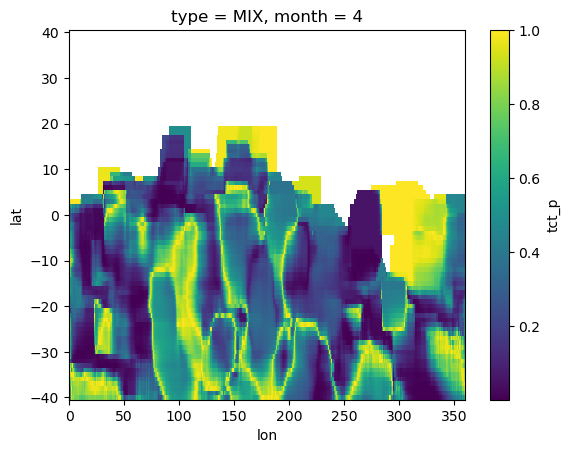

In [52]:
ds_nino.tct_p[0, 10].loc[-40:40].plot()

In [11]:
# combine heat flux
lon = np.arange(120, 281)
lat = np.arange(-40, 41)
time_all = pd.date_range('1900-01', '2010-12', freq='MS')
nt = len(time_all)
ny = len(lat)
nx = len(lon)

ds_net_Q = xr.Dataset(
   {
       'sw':(['time', 'lat', 'lon'], np.empty((nt, ny, nx))),
       'lw':(['time', 'lat', 'lon'], np.empty((nt, ny, nx))),
       'sh':(['time', 'lat', 'lon'], np.empty((nt, ny, nx))),
       'lh':(['time', 'lat', 'lon'], np.empty((nt, ny, nx))),
   },
   coords={
        'time':(['time'], time_all),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)

ds = xr.open_dataset(path_noaa+'dswrf.sfc.mon.mean.nc').dswrf
dl = xr.open_dataset(path_noaa+'dlwrf.sfc.mon.mean.nc').dlwrf
us = xr.open_dataset(path_noaa+'uswrf.sfc.mon.mean.nc').uswrf
ul = xr.open_dataset(path_noaa+'ulwrf.sfc.mon.mean.nc').ulwrf
sh = xr.open_dataset(path_noaa+'shtfl.mon.mean.nc').shtfl
lh = xr.open_dataset(path_noaa+'lhtfl.mon.mean.nc').lhtfl

net_s = ds - us
net_l = dl - ul


ds_net_Q.sw[:, :, :] = net_s.values
ds_net_Q.lw[:, :, :] = net_l.values
ds_net_Q.sh[:, :, :] = -sh.values
ds_net_Q.lh[:, :, :] = -lh.values


ds_net_Q.to_netcdf('./data-20c/Qnet.nc')

In [2]:
ds_t = xr.open_dataset(soda_path+'soda.temp.nc')
ds_u = xr.open_dataset(soda_path+'soda.ucur.nc')
ds_v = xr.open_dataset(soda_path+'soda.vcur.nc')
ds_w = xr.open_dataset(soda_path+'soda.wcur.nc')

temp = ds_t.TEMP
ucur = ds_u.U
vcur = ds_v.V
wcur = ds_w.W
level = [5.01, 15.07, 25.28, 35.76, 46.61, 57.98, 70.02, 82.92, 96.92, 112.32, 129.49, 148.96, 171.4, 197.79 ]

temp = temp.assign_coords(level=level).rename({'TIME':'time'})
ucur = ucur.assign_coords(level=level).rename({'TIME':'time'})
vcur = vcur.assign_coords(level=level).rename({'TIME':'time'})
wcur = wcur.assign_coords(level=level).rename({'TIME':'time'})

# mixed layer heat budget equation
# take the mixed layer depth equal to 45m
# unit: K/month
lon = np.arange(120, 281)
lat = np.arange(-40, 41)
time_all = pd.date_range('1900-01', '2011-01', freq='M')
nt = len(time_all)
ny = len(lat)
nx = len(lon)

ds_dTdt = xr.Dataset(
   {
       'MLHB':(['time', 'term', 'lat', 'lon'], np.empty((nt, 15, ny, nx))),
   },
   coords={
        'time':(['time'], time_all),
        'term':(['term'], ['dT/dt', '-Utx', '-uTx', '-utx', '-Vty', '-vTy', '-vty', '-Wtz', '-wTz', '-wtz', 'SW', 'LW', 'SH', 'LH', 'R']),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)

rolling = lambda x: x.rolling(time=30, min_periods=1, center=True).mean()
a = 6.4e+6
# compute dT/dt
T = temp.loc[:, 0:30, :, :].mean(dim='level')
ML_T = T.groupby('time.month').map(rolling)
ML_t = T - ML_T
ds_dTdt.MLHB[:, 0, :, :] = ML_t.assign_coords(time=np.arange(1332)).differentiate('time').values

# compute zonal adv
fac = 30*24*3600/(np.pi/180*a)
U_ = ucur.loc[:, 0:30, :, :].mean(dim='level')
U = U_.groupby('time.month').map(rolling)
u = U_ - U
ds_dTdt.MLHB[:, 1, :, :] = -U.values * ML_t[:].differentiate('lon').values*fac
ds_dTdt.MLHB[:, 2, :, :] = -u.values * ML_T[:].differentiate('lon').values*fac
ds_dTdt.MLHB[:, 3, :, :] = -u.values * ML_t[:].differentiate('lon').values*fac

# compute zonal adv
fac = 30*24*3600/(np.pi/180*a)
V_ = vcur.loc[:, 0:30, :, :].mean(dim='level')
V = V_.groupby('time.month').map(rolling)
v = V_ - V
ds_dTdt.MLHB[:, 4, :, :] = -V.values * ML_t[:].differentiate('lat').values*fac
ds_dTdt.MLHB[:, 5, :, :] = -v.values * ML_T[:].differentiate('lat').values*fac
ds_dTdt.MLHB[:, 6, :, :] = -v.values * ML_t[:].differentiate('lat').values*fac

# compute vertical adv
fac = 31*24*3600

ML_T = temp.loc[:, 0:30, :, :]
T = ML_T.groupby('time.month').map(rolling)
t = ML_T - T
Tsub = T[:, -1].values
tsub = t[:, -1].values
T = T.mean(dim='level').values
t = t.mean(dim='level').values

ML_w = wcur.loc[:, 0:30, :, :].mean(dim='level')
W = ML_w.groupby('time.month').map(rolling)
w = ML_w - W

ds_dTdt.MLHB[:, 7, :, :] = -W.values * (t - tsub)/(15) *fac
ds_dTdt.MLHB[:, 8, :, :] = -w.values * (T - Tsub)/(15) *fac
ds_dTdt.MLHB[:, 9, :, :] = -w.values * (t - tsub)/(15) *fac

# compute Qnet
ds_Qnet = xr.open_dataset('./data-20c/Qnet.nc')
fac = 30*1025*4096/(30*24*3600)
SW = ds_Qnet.sw.groupby('time.month').map(rolling)
LW = ds_Qnet.lw.groupby('time.month').map(rolling)
SH = ds_Qnet.sh.groupby('time.month').map(rolling)
LH = ds_Qnet.lh.groupby('time.month').map(rolling)

sw = ds_Qnet.sw  -SW
lw = ds_Qnet.lw  -LW
sh = ds_Qnet.sh  -SH
lh = ds_Qnet.lh  -LH

ds_dTdt.MLHB[:, 10, :, :] = sw.values/fac
ds_dTdt.MLHB[:, 11, :, :] = lw.values/fac
ds_dTdt.MLHB[:, 12, :, :] = sh.values/fac
ds_dTdt.MLHB[:, 13, :, :] = lh.values/fac

ds_dTdt.MLHB[:, -1, :, :] = ds_dTdt.MLHB[:, 0, :, :] - ds_dTdt.MLHB[:, 1:-1, :, :].sum(dim='term')

ds_dTdt.to_netcdf('./data-20c/dTdt.nc')


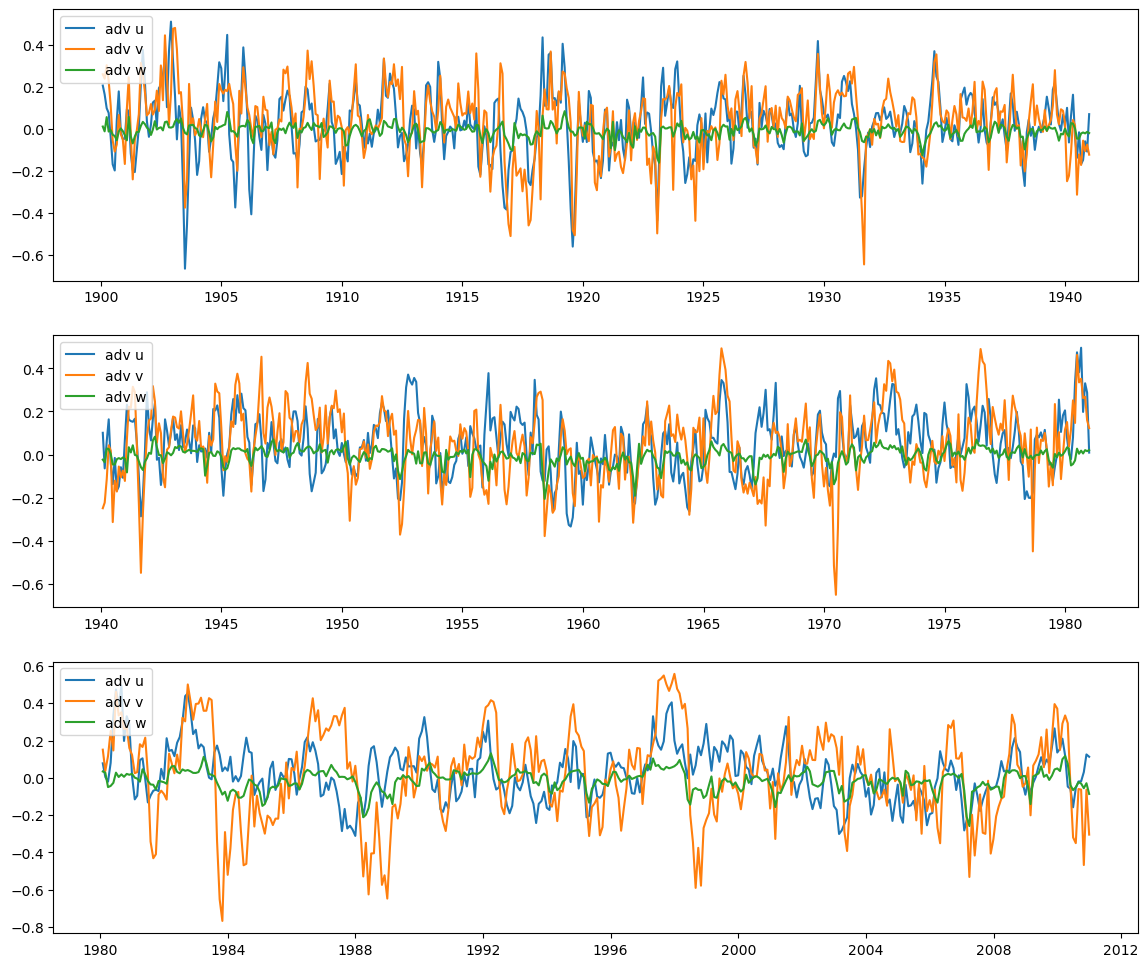

In [3]:
fig, axs = plt.subplots(3 ,1, figsize=(14, 12))
mlhb = ds_dTdt.MLHB.loc[:, :, -5:5, 180:280].mean(dim=['lat', 'lon'])
datas = [mlhb.loc[:'1940'], mlhb.loc['1940':'1980'], mlhb.loc['1980':]]
for i in range(3):
    ax = axs[i]
    data = datas[i]
    # ax.plot(data.time, data[:, 0], color='k', label='dTdt')
    ax.plot(data.time, data[:, 1:4].sum(dim='term'), label='adv u')
    ax.plot(data.time, data[:, 4:7].sum(dim='term'), label='adv v')
    ax.plot(data.time, data[:, 7:10].sum(dim='term'), label='adv w')
    # ax.plot(data.time, data[:, 1:14].sum(dim='term'), color='r', label='mlhb')
    # ax.plot(data.time, data[:, 1:10].sum(dim='term'), label='adv')
    # ax.plot(data.time, data[:, 10:14].sum(dim='term'), label='hflx')
    ax.legend(loc='upper left')
# fig.savefig('./pic-20c/time series mlhb adv each.png', dpi=300)

In [2]:
xr.open_dataset('./data-20c/NOAA-20C_TC_grid.nc')

<xarray.Dataset>
Dimensions:         (time: 2520, lat: 181, lon: 361, basin: 6)
Coordinates:
  * basin           (basin) object 'SH' 'NS' 'NI' 'WNP' 'ENP' 'NA'
  * time            (time) datetime64[ns] 1806-01-01 1806-02-01 ... 2015-12-01
  * lat             (lat) int32 -90 -89 -88 -87 -86 -85 ... 85 86 87 88 89 90
  * lon             (lon) int32 0 1 2 3 4 5 6 7 ... 354 355 356 357 358 359 360
Data variables:
    tcg_grid        (time, lat, lon) float64 ...
    tcg_current     (basin, time) float64 ...
    tcg_series      (basin, time) float64 ...
    tcg_series_max  (basin, time) float64 ...
    tcg_series_min  (basin, time) float64 ...

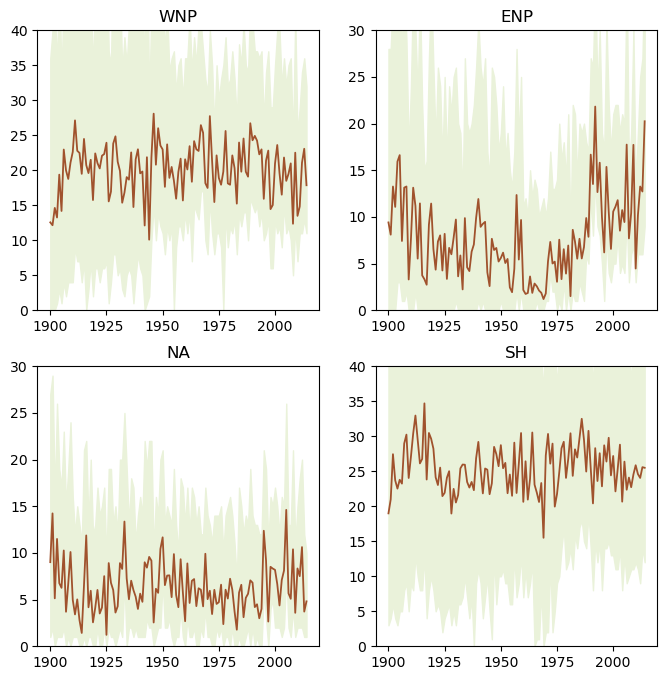

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(8, 8))
ds_tc = xr.open_dataset('./data-20c/NOAA-20C_TC_grid.nc').sel(time=slice('1900-01', None))
basin = [3, 4, 5, 0]
series = ds_tc.tcg_series[basin, :].coarsen(time=12).sum()[:, :-1]
series_max = ds_tc.tcg_series_max[basin, :].coarsen(time=12).sum()[:, :-1]
series_min = ds_tc.tcg_series_min[basin, :].coarsen(time=12).sum()[:, :-1]
time = series.time.dt.year
titles = series.basin.values
ylim = [[0, 40], [0, 30], [0, 30], [0, 40]]
for i, ax in enumerate(axs.flatten()):
    ax.plot(time, series[i], linewidth=1.3, color='sienna')
    ax.fill_between(time, series_max[i], series_min[i], color='#EAF2DA')
    ax.set_ylim(ylim[i])
    ax.set_title(titles[i], fontsize=12)
fig.savefig('./pic-20c/NOAA-20C_TC_series_org.png', dpi=300)

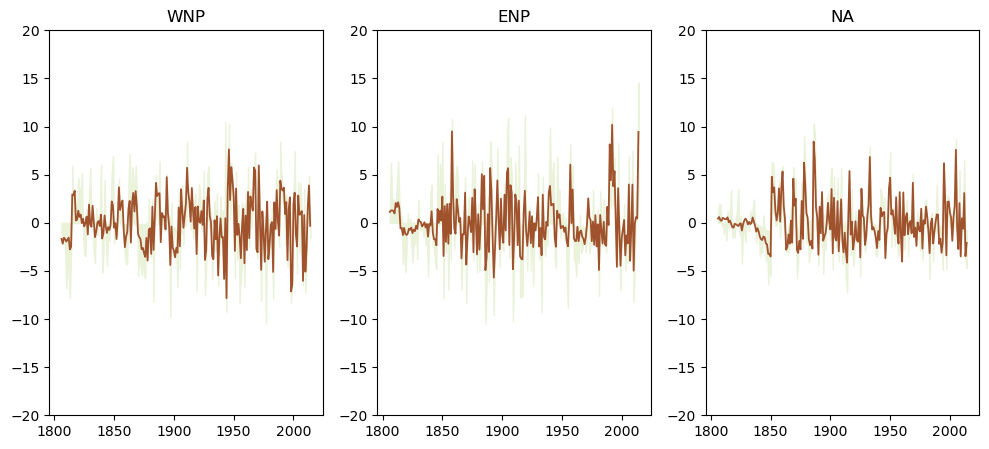

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(12, 5))
series = ds_tc.tcg_series[[3, 4, 5], :].coarsen(time=12).sum()[:, :-1]
series_max = ds_tc.tcg_series_max[[3, 4, 5], :].coarsen(time=12).sum()[:, :-1]
series_min = ds_tc.tcg_series_min[[3, 4, 5], :].coarsen(time=12).sum()[:, :-1]

series -= series.rolling(time=30, min_periods=1,center=True).mean()
series_max -= series_max.rolling(time=30, min_periods=1,center=True).mean()
series_min -= series_min.rolling(time=30, min_periods=1,center=True).mean()
time = series.time.dt.year
titles = ['WNP', 'ENP', 'NA']
ylim = [[-20, 20], [-20, 20], [-20, 20]]
for i, ax in enumerate(axs.flatten()):
    ax.plot(time, series[i], linewidth=1.3, color='sienna')
    ax.fill_between(time, series_max[i], series_min[i], color='#EAF2DA')
    ax.set_ylim(ylim[i])
    ax.set_title(titles[i], fontsize=12)
# fig.savefig('./pic-20c/NOAA-20C_TC_series.png', dpi=300)